<a href="https://colab.research.google.com/github/adperez-lab/Proyecto-Aula-EDO-Grupo3/blob/main/comprobacion_RL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sympy as sp

t = sp.symbols('t')
y = sp.symbols('y')              # y representa a la corriente i
R, L, E0 = sp.symbols('R L E0', positive=True)
c = sp.symbols('c')

# P1: forma diferencial M dt + N di = 0
M = R*y - E0
N = L

# P2: criterio de exactitud
print("M_i =", sp.diff(M, y), "| N_t =", sp.diff(N, t))

# P3: factor integrante
g = sp.simplify((sp.diff(M, y) - sp.diff(N, t)) / N)
mu = sp.exp(sp.integrate(g, t))
print("g(t) =", g, "| mu =", mu)

# P4: ecuación multiplicada por mu, verificar que es exacta
Mt = sp.simplify(mu*M)
Nt = sp.simplify(mu*N)
print("Exacta?:", sp.simplify(sp.diff(Mt, y) - sp.diff(Nt, t)) == 0)

# P5: hallar F(t, i)
F = sp.integrate(Nt, y)
h = sp.integrate(sp.simplify(Mt - sp.diff(F, t)), t)
F = sp.simplify(F + h)
print("F =", F)

# P6 y P7: despejar i con F = c y aplicar i(0) = 0
i_expr = sp.solve(sp.Eq(F, c), y)[0]
c0 = sp.solve(sp.Eq(i_expr.subs(t, 0), 0), c)[0]
i_manual = sp.simplify(i_expr.subs(c, c0))
print("Solución a mano: i(t) =", i_manual)

# Comparar con la solución directa de SymPy
i = sp.Function('i')
ed = sp.Eq(L*i(t).diff(t) + R*i(t), E0)
sol = sp.dsolve(ed, i(t), ics={i(0): 0})
print("dsolve:", sol)
print("Diferencia (debe dar 0):", sp.simplify(sol.rhs - i_manual))

M_i = R | N_t = 0
g(t) = R/L | mu = exp(R*t/L)
Exacta?: True
F = L*(-E0 + R*y)*exp(R*t/L)/R
Solución a mano: i(t) = E0/R - E0*exp(-R*t/L)/R
dsolve: Eq(i(t), E0/R - E0*exp(-R*t/L)/R)
Diferencia (debe dar 0): 0


Error máximo: 3.7919356543625327e-10
i(0.2) = 1.2642
i(0.4) = 1.7293
i(1.0) = 1.9865


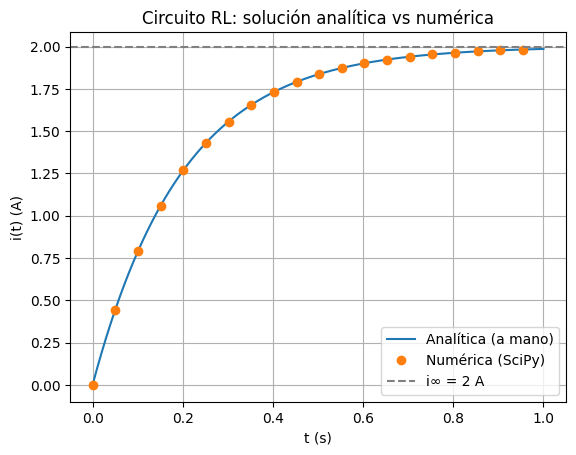

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

Rv, Lv, Ev = 10, 2, 20

# Solución analítica (la del papel)
def i_analitica(t):
    return (Ev/Rv) * (1 - np.exp(-Rv*t/Lv))

# Solución numérica de L di/dt + R i = E0 con i(0) = 0
tt = np.linspace(0, 1, 200)
num = solve_ivp(lambda t, i: (Ev - Rv*i)/Lv, (0, 1), [0],
                t_eval=tt, rtol=1e-9, atol=1e-12)

print("Error máximo:", np.max(np.abs(num.y[0] - i_analitica(tt))))
for tv in [0.2, 0.4, 1.0]:
    print(f"i({tv}) =", round(float(i_analitica(tv)), 4))

plt.plot(tt, i_analitica(tt), label="Analítica (a mano)")
plt.plot(tt[::10], num.y[0][::10], 'o', label="Numérica (SciPy)")
plt.axhline(Ev/Rv, linestyle='--', color='gray', label="i∞ = 2 A")
plt.xlabel("t (s)")
plt.ylabel("i(t) (A)")
plt.title("Circuito RL: solución analítica vs numérica")
plt.legend()
plt.grid(True)
plt.show()